# 03. Нейросеть DCN: признаки и обучаемые взаимодействия

DCN — Deep & Cross Network, нейросеть с двумя ветками. Обычная полносвязная ветка, или MLP, учит нелинейные зависимости. Cross-ветка учит произведения и сочетания входов. Категория сначала превращается в embedding — небольшой обучаемый набор чисел, с которым сеть может считать.

Здесь два отдельных вопроса: помогают ли добавленные вручную признаки и помогает ли сама cross-ветка. Поэтому обучаем четыре модели: MLP и DCN, каждую на базовых полях и с FE.

## Две версии одной модели

| Версия | Что видит модель |
|---|---|
| Базовые поля, 5 входов | Склад, артикул, два уровня категории и характеристика товара |
| С FE, 50 входов | Те же поля + календарь, история продаж, вчерашние остатки, общие продажи склада/товара и явные сочетания |

Внутри пары одинаковы обучающие строки, временные границы, функция потерь и правило выбора момента остановки. Меняется набор входов. FE — создание дополнительных признаков; все определения есть в [словаре](../features/FEATURES.md). Подготовка нулевых дней нужна обеим версиям и не считается различием между ними.

**Как читаем качество.** MAE — средняя абсолютная ошибка в штуках; меньше лучше. WAPE — суммарная абсолютная ошибка / суммарные продажи, в таблицах это доля. RMSE сильнее штрафует большие ошибки. RMSLE считает ошибку в логарифмической шкале. Смещение (bias) — средний прогноз минус факт; отрицательное значение означает недопрогноз. Валидация выбирает настройки, тест проверяет уже выбранную модель.


У обеих версий одинаковы ширины скрытых слоёв 64 → 32, до пяти эпох, размер пакета, оптимизатор и цель обучения. Внутри DCN сохраняются два cross-слоя. Поскольку число входов различается, размеры входных матриц закономерно отличаются.

Сеть обучаем на `log1p(quantity)` — логарифме единицы плюс количество. Он уменьшает влияние редких больших продаж. Лучший момент обучения выбираем по MAE в исходных штуках на валидации. Обратное преобразование может занижать средний объём — проверяем смещение.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
OUT=ROOT/'data/artifacts/training'; MODELS=ROOT/'data/models'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
frames={s:pd.read_parquet(PROCESSED/f'{s}.parquet') for s in ['train','valid','test']}
FEATURE_SETS=manifest['feature_sets']
ALL_CATS=FEATURE_SETS['fe']['categorical']
for df in frames.values():
    for c in ALL_CATS: df[c]=df[c].astype('string').fillna('__MISSING__').astype(str)
assert frames['train'].date.max()<frames['valid'].date.min()<frames['test'].date.min()
assert set(FEATURE_SETS['base']['categorical'])<=set(ALL_CATS)

def metrics(y,pred):
    y=np.asarray(y,dtype='float64'); pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert np.isfinite(pred).all() and len(y)==len(pred)
    return {'MAE':float(mean_absolute_error(y,pred)),
            'WAPE':float(np.abs(y-pred).sum()/y.sum()) if y.sum()>0 else np.nan,
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'RMSLE':float(np.sqrt(mean_squared_log_error(y,pred))),
            'bias':float(np.mean(pred-y))}

def save_result(name,predictions,seconds,family,setting,columns,params):
    records=[]; output=[]
    for split,pred in predictions.items():
        pred=np.maximum(np.asarray(pred),0)
        records.append({'model':name,'family':family,'feature_set':setting,'feature_count':len(columns),
                        'split':split,**metrics(frames[split].quantity,pred),'fit_seconds':float(seconds)})
        p=frames[split][['date','pair_id','quantity']].copy(); p['prediction']=pred; p['split']=split; output.append(p)
    result=pd.DataFrame(records)
    result.to_csv(OUT/f'{name}_metrics.csv',index=False)
    pd.concat(output,ignore_index=True).to_parquet(PROCESSED/f'{name}_predictions.parquet',index=False)
    contract={'model':name,'family':family,'feature_set':setting,'features':columns,'parameters':params,
              'seed':SEED,'train_rows':len(frames['train']),
              'train_end':manifest['train_end'],'valid_start':manifest['valid_start'],'test_start':manifest['test_start']}
    (OUT/f'{name}_experiment.json').write_text(json.dumps(contract,indent=2,ensure_ascii=False))
    display_ru(result.round(5))
    return result

def show_pair(family):
    rows=pd.concat([pd.read_csv(OUT/f'{family}_{s}_metrics.csv') for s in ['base','fe']])
    display_ru(rows[['model','feature_count','split','MAE','WAPE','RMSE','bias']].round(5))
    for split in ['valid','test']:
        p=rows[rows.split.eq(split)].set_index('feature_set')
        gain=100*(1-p.loc['fe','MAE']/p.loc['base','MAE'])
        display(Markdown(f"**{MODEL_LABELS[split]}:** MAE меняется с {p.loc['base','MAE']:.4f} до {p.loc['fe','MAE']:.4f}; улучшение {gain:+.1f}%. Плюс означает уменьшение ошибки."))
    return rows

def fit_plot(y,pred,title,filename):
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    z=pd.DataFrame({'actual':np.asarray(y),'predicted':np.maximum(pred,0)})
    z['bin']=pd.cut(z.predicted,[-.001,.1,.25,.5,1,2,4,8,16,np.inf])
    calibration=z.groupby('bin',observed=True).agg(actual=('actual','mean'),predicted=('predicted','mean'))
    axes[0].plot(calibration.predicted,calibration.actual,'o-')
    mx=max(calibration.predicted.max(),calibration.actual.max()); axes[0].plot([0,mx],[0,mx],'--',alpha=.5)
    axes[0].set(xlabel='Средний прогноз',ylabel='Средний факт',title='Калибровка: совпадает ли прогноз с фактом')
    residual=z.predicted-z.actual
    axes[1].hist(residual.clip(residual.quantile(.01),residual.quantile(.99)),bins=60)
    axes[1].set(xlabel='Прогноз минус факт: центральные 98%',title=title)
    plt.tight_layout(); plt.savefig(OUT/filename,dpi=160,bbox_inches='tight'); plt.show()

display_ru(pd.DataFrame([{'split':s,'rows':len(f),'date_min':f.date.min().date(),'date_max':f.date.max().date()} for s,f in frames.items()]))
print('Протокол: прогноз на день по данным, известным по конец предыдущего дня.')

import random
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import joblib
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(8)
DEVICE=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Устройство: GPU Apple' if DEVICE.type=='mps' else 'Устройство: CPU')

,Период,Число строк,Первая дата,Последняя дата
0,Обучение,600000,2024-01-29,2026-06-05
1,Валидация,245758,2026-06-06,2026-07-03
2,Тест,245784,2026-07-04,2026-07-31


Протокол: прогноз на день по данным, известным по конец предыдущего дня.


Устройство: GPU Apple


## Подготовка категорий и чисел

Словарь категорий учим только на обучении; новому значению даём индекс 0. У базовой версии числовых входов нет. У версии с FE ограничиваем редкие числовые хвосты квантилями обучения, заменяем пропуски медианами и добавляем флаги пропусков, затем масштабируем.

Все шаги выполняются отдельно для каждого набора входов. Валидация и тест не меняют словари, границы или средние.

In [2]:
def prepare(spec):
    cats=spec['categorical']; nums=spec['numeric']; train=frames['train']
    maps={c:{v:i+1 for i,v in enumerate(sorted(train[c].unique()))} for c in cats}
    cardinalities=[len(maps[c])+1 for c in cats]
    low=high=imputer=scaler=None
    if nums:
        low=train[nums].quantile(.001); high=train[nums].quantile(.999)
        imputer=SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)
        scaler=StandardScaler()
        train_num=scaler.fit_transform(imputer.fit_transform(train[nums].clip(lower=low,upper=high,axis=1))).astype('float32')
    else:
        train_num=np.empty((len(train),0),dtype='float32')
    arrays={}
    for split,df in frames.items():
        if split=='train': numeric=train_num
        elif nums: numeric=scaler.transform(imputer.transform(df[nums].clip(lower=low,upper=high,axis=1))).astype('float32')
        else: numeric=np.empty((len(df),0),dtype='float32')
        categorical=np.column_stack([df[c].map(maps[c]).fillna(0).to_numpy(dtype='int64') for c in cats])
        arrays[split]=(torch.from_numpy(categorical).to(DEVICE),torch.from_numpy(numeric).to(DEVICE),
                       torch.from_numpy(np.log1p(df.quantity.to_numpy(dtype='float32'))).to(DEVICE))
    prep={'category_maps':maps,'low':low,'high':high,'imputer':imputer,'scaler':scaler,'categorical':cats,'numeric':nums}
    return arrays,cardinalities,train_num.shape[1],prep

## Что делает cross-слой

Один слой вычисляет `x₀ · (wᵀx) + b + x`: исходные входы умножаются на обучаемую комбинацию текущих входов, затем добавляются смещение и предыдущий результат. Это позволяет учить взаимодействия без ручного перечисления всех произведений. MLP для проверки ниже получает те же данные, но у неё этой ветки нет.

In [3]:
class CrossLayer(nn.Module):
    def __init__(self,dimension):
        super().__init__()
        self.weight=nn.Parameter(torch.randn(dimension)*.01)
        self.bias=nn.Parameter(torch.zeros(dimension))
    def forward(self,x0,x):
        return x0*(x@self.weight).unsqueeze(1)+self.bias+x

class DeepCrossNetwork(nn.Module):
    def __init__(self,cardinalities,n_numeric,cross_layers=2):
        super().__init__()
        dimensions=[min(16,max(4,int(n**.25*2))) for n in cardinalities]
        self.embeddings=nn.ModuleList([nn.Embedding(n,d,padding_idx=0) for n,d in zip(cardinalities,dimensions)])
        dimension=sum(dimensions)+n_numeric
        self.crosses=nn.ModuleList([CrossLayer(dimension) for _ in range(cross_layers)])
        self.deep=nn.Sequential(nn.Linear(dimension,64),nn.ReLU(),nn.Dropout(.1),nn.Linear(64,32),nn.ReLU())
        self.head=nn.Linear(32+(dimension if cross_layers else 0),1)
    def forward(self,categorical,numeric):
        x0=torch.cat([*[embedding(categorical[:,i]) for i,embedding in enumerate(self.embeddings)],numeric],dim=1)
        deep=self.deep(x0)
        if self.crosses:
            cross=x0
            for layer in self.crosses: cross=layer(x0,cross)
            deep=torch.cat([deep,cross],dim=1)
        return self.head(deep).squeeze(1)


@torch.no_grad()
def predict(net,data,batch_size=8192):
    net.eval(); categorical,numeric,_=data; preds=[]
    for start in range(0,len(categorical),batch_size):
        raw=net(categorical[start:start+batch_size],numeric[start:start+batch_size])
        preds.append(torch.expm1(raw.clamp(0,12)).cpu().numpy())
    return np.concatenate(preds)

## Две пары моделей на одинаковых строках

Эпоха — один проход по обучающим строкам. Пакет (batch) — часть строк одного шага оптимизатора. Все модели обучаются до пяти эпох; сохраняем состояние с минимальной MAE на валидации. Число эпох и правило выбора одинаковы. Тест не используется для остановки.

In [4]:
EPOCHS=5; BATCH_SIZE=4096
all_history=[]; predictions_by_name={}
params={'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':.001,'weight_decay':1e-4,
        'hidden_widths':[64,32],'target_transform':'log1p','loss':'MSE(log1p quantity)'}
for setting,spec in FEATURE_SETS.items():
    arrays,cardinalities,n_numeric,preprocessor=prepare(spec)
    for family,cross_layers in [('mlp',0),('dcn',2)]:
        torch.manual_seed(SEED)
        name=f'{family}_{setting}'
        net=DeepCrossNetwork(cardinalities,n_numeric,cross_layers).to(DEVICE)
        optimizer=torch.optim.AdamW(net.parameters(),lr=.001,weight_decay=1e-4)
        loss_fn=nn.MSELoss(); best_mae=np.inf; best_state=None
        start=time.perf_counter(); x_cat,x_num,y=arrays['train']
        for epoch in range(1,EPOCHS+1):
            net.train(); order=torch.randperm(len(y),device=DEVICE); loss_sum=0
            for first in range(0,len(y),BATCH_SIZE):
                ids=order[first:first+BATCH_SIZE]; optimizer.zero_grad(set_to_none=True)
                loss=loss_fn(net(x_cat[ids],x_num[ids]),y[ids])
                assert torch.isfinite(loss), 'Ошибка обучения стала нечисловой'
                loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),5.0); optimizer.step()
                loss_sum+=float(loss.detach().cpu())*len(ids)
            score=metrics(frames['valid'].quantity,predict(net,arrays['valid']))
            all_history.append({'model':name,'epoch':epoch,'train_log_mse':loss_sum/len(y),**score})
            print(f"{MODEL_LABELS[name]}, эпоха {epoch}: MAE={score['MAE']:.4f}",flush=True)
            if score['MAE']<best_mae:
                best_mae=score['MAE']; best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
        elapsed=time.perf_counter()-start; net.load_state_dict(best_state)
        predictions={s:predict(net,arrays[s]) for s in ['valid','test']}
        save_result(name,predictions,elapsed,family,setting,spec['categorical']+spec['numeric'],dict(params,cross_layers=cross_layers))
        predictions_by_name[name]=predictions
        torch.save({'state_dict':best_state,'cardinalities':cardinalities,'n_numeric':n_numeric,'cross_layers':cross_layers,
                    'categorical':spec['categorical'],'numeric':spec['numeric'],'target_transform':'log1p'},MODELS/f'{name}.pt')
        joblib.dump(preprocessor,MODELS/f'{name}_preprocessor.joblib')
history=pd.DataFrame(all_history); history.to_csv(OUT/'dcn_learning_curve.csv',index=False)
show_pair('dcn'); show_pair('mlp')

MLP: базовые поля, эпоха 1: MAE=0.4328


MLP: базовые поля, эпоха 2: MAE=0.4043


MLP: базовые поля, эпоха 3: MAE=0.3813


MLP: базовые поля, эпоха 4: MAE=0.3772


MLP: базовые поля, эпоха 5: MAE=0.3723


...

**Тест:** MAE меняется с 0.3995 до 0.3356; улучшение +16.0%. Плюс означает уменьшение ошибки.

,Модель,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.","Смещение, шт."
0,MLP: базовые поля,5,Валидация,0.37225,0.97677,1.10594,-0.21121
1,MLP: базовые поля,5,Тест,0.39034,0.97652,1.17331,-0.22984
0,MLP: с FE,50,Валидация,0.32038,0.84066,0.84869,-0.09304
1,MLP: с FE,50,Тест,0.33286,0.83274,0.86903,-0.09198


**Валидация:** MAE меняется с 0.3723 до 0.3204; улучшение +13.9%. Плюс означает уменьшение ошибки.

**Тест:** MAE меняется с 0.3903 до 0.3329; улучшение +14.7%. Плюс означает уменьшение ошибки.

,model,Семейство модели,Набор входов,feature_count,split,MAE,WAPE,RMSE,RMSLE,bias,fit_seconds
0,mlp_base,mlp,base,5,valid,0.372254,0.976771,1.105945,0.344545,-0.211211,2.382382
1,mlp_base,mlp,base,5,test,0.390337,0.976524,1.173310,0.356028,-0.229843,2.382382
0,mlp_fe,mlp,fe,50,valid,0.320381,0.840659,0.848693,0.295250,-0.093038,3.602255
1,mlp_fe,mlp,fe,50,test,0.332864,0.832741,0.869028,0.299602,-0.091975,3.602255


## Как разделяем два эффекта

**DCN: база → FE** показывает пользу ручных признаков при одной архитектуре. **MLP: база → FE** проверяет то же без cross-ветки. **MLP → DCN при одном наборе** показывает вклад обучаемой cross-ветки. Это один seed и короткое обучение; небольшую разницу нельзя считать устойчивым преимуществом.

,Модель,Эпоха,"MAE, шт.","RMSE, шт.","Смещение, шт."
9,DCN: базовые поля,5,0.38124,1.13188,-0.21210
15,DCN: с FE,1,0.32311,0.85253,-0.08673
4,MLP: базовые поля,5,0.37225,1.10594,-0.21121
10,MLP: с FE,1,0.32038,0.84869,-0.09304


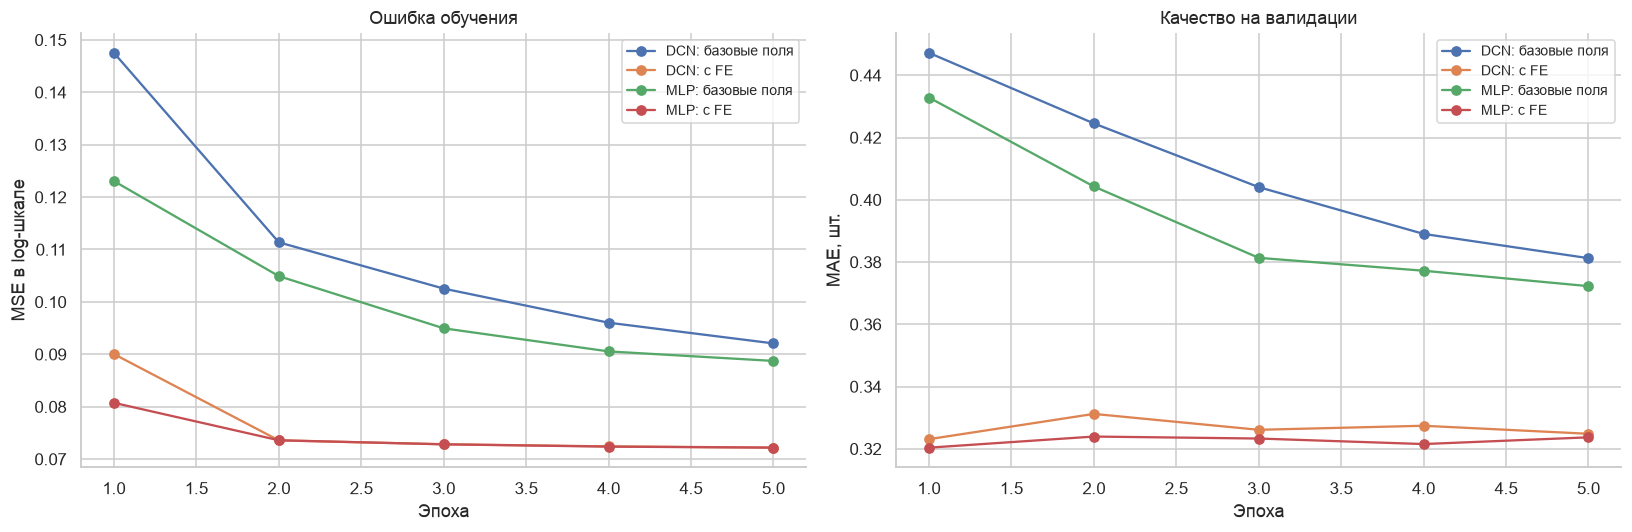

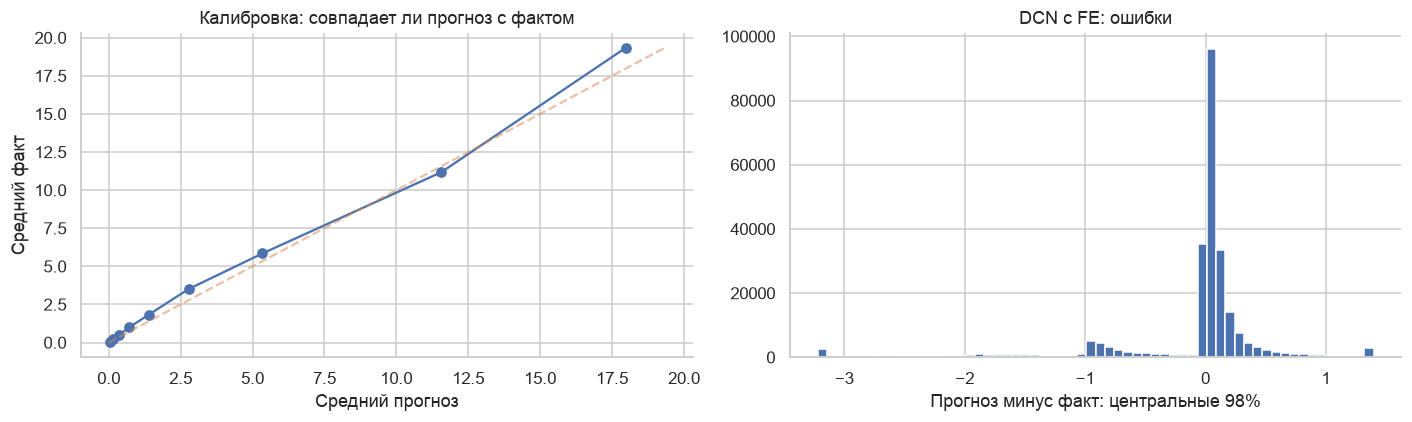

In [5]:
best_epochs=history.loc[history.groupby('model').MAE.idxmin()]
display_ru(best_epochs[['model','epoch','MAE','RMSE','bias']].round(5))
fig,axes=plt.subplots(1,2,figsize=(15,5))
for name,g in history.groupby('model'):
    axes[0].plot(g.epoch,g.train_log_mse,'o-',label=MODEL_LABELS[name])
    axes[1].plot(g.epoch,g.MAE,'o-',label=MODEL_LABELS[name])
axes[0].set(title='Ошибка обучения',xlabel='Эпоха',ylabel='MSE в log-шкале'); axes[0].legend(fontsize=9)
axes[1].set(title='Качество на валидации',xlabel='Эпоха',ylabel='MAE, шт.'); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT/'05_dcn_learning.png',dpi=160,bbox_inches='tight'); plt.show()
fit_plot(frames['test'].quantity,predictions_by_name['dcn_fe']['test'],'DCN с FE: ошибки','06_dcn_calibration.png')